# Generic-orbit validation vs pybhpt (independent implementation)

Per-mode cross-check of the batched 2D-torus integrator against the
committed pybhpt snapshot (`tests/golden/pybhpt_reference_v1.npz`):
amplitude gate, all six flux channels incl. the Carter flux, the
scan-contraction vs full-ifft2 identity, conjugate symmetry, and a
coarse-grid error-estimate audit. All gates asserted.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from hblteuk.geo import MiniGeo
from hblteuk.jax import solve_generic_mode_table, flux_modes

ref = np.load("../tests/golden/pybhpt_reference_v1.npz")
t = ref["gen_table"]
l, m, k, n = (t[:, i].astype(int) for i in (0, 1, 2, 3))
zin = t[:, 6] + 1j * t[:, 7]
zup = t[:, 8] + 1j * t[:, 9]
orbit = MiniGeo(*ref["gen_params"])
sol = solve_generic_mode_table(orbit, -2, l, m, k, n,
                               nsamples=2**9, ntheta=2**7)
amps = np.asarray(sol.amplitudes)

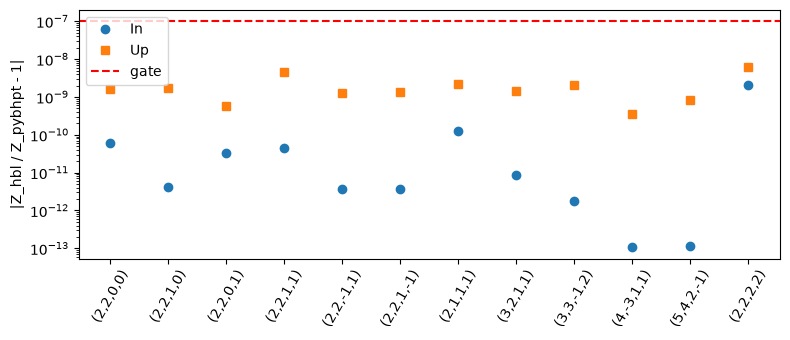

worst: In 2.02e-09, Up 6.36e-09


In [2]:
rel_in = np.abs(amps[:, 0] / zin - 1)
rel_up = np.abs(amps[:, 1] / zup - 1)
labels = [f"({a},{b},{c},{d})" for a, b, c, d in zip(l, m, k, n)]
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.semilogy(rel_in, "o", label="In"); ax.semilogy(rel_up, "s", label="Up")
ax.set_xticks(range(len(labels)), labels, rotation=60)
ax.axhline(1e-7, color="r", ls="--", label="gate")
ax.set_ylabel("|Z_hbl / Z_pybhpt - 1|"); ax.legend()
plt.tight_layout(); plt.show()
print(f"worst: In {rel_in.max():.2e}, Up {rel_up.max():.2e}")
assert rel_in.max() < 1e-7 and rel_up.max() < 1e-7

In [3]:
fx = flux_modes(sol.amplitudes, sol.m, sol.omega, sol.eigenvalues,
                orbit.a, k=sol.k, n=sol.n,
                carter_frequencies=orbit.carter_frequencies())
Edot, Ldot, Qdot = (np.asarray(fx.Edot), np.asarray(fx.Ldot),
                    np.asarray(fx.Qdot))
for col, ours, name in [(10, Edot[:, 0], "Edot_inf"), (11, Edot[:, 1], "Edot_hor"),
                        (12, Ldot[:, 0], "Ldot_inf"), (13, Ldot[:, 1], "Ldot_hor"),
                        (14, Qdot[:, 0], "Qdot_inf"), (15, Qdot[:, 1], "Qdot_hor")]:
    rel = np.max(np.abs(ours / t[:, col] - 1))
    print(f"{name}: max rel diff {rel:.2e}")
    assert rel < 1e-7
print(f"superradiant modes in table: {(Edot[:, 1] < 0).sum()}")

Edot_inf: max rel diff 1.09e-08
Edot_hor: max rel diff 2.62e-09
Ldot_inf: max rel diff 1.09e-08
Ldot_hor: max rel diff 2.62e-09
Qdot_inf: max rel diff 1.09e-08
Qdot_hor: max rel diff 2.62e-09
superradiant modes in table: 12


In [4]:
from hblteuk.jax.source import (generic_samples,
                                integrate_source_generic_batch,
                                polar_swsh_values)
from hblteuk.jax import solve_homogeneous_batch, spheroidal_eigs_batched
from hblteuk.collocode import generate_subdomain_list
from hblteuk.teuk import sigma_r

om = sol.omega
a = orbit.a; kappa = np.sqrt(1 - a**2)
lam, coeffs, lmin = spheroidal_eigs_batched(-2, l, m, a * om)
lam = np.asarray(lam); coeffs = np.asarray(coeffs)
su = generate_subdomain_list([0, sigma_r(orbit.radial_roots[1], kappa)], 150, "arcsinh7")
si = generate_subdomain_list([1, sigma_r(orbit.radial_roots[0], kappa)], 150, "arcsinh7")
hom = solve_homogeneous_batch(-2, kappa, lam, m * a, om, su, si)
smp = generic_samples(orbit, nsamples=2**9, ntheta=2**7)
S, dS, d2S = polar_swsh_values(-2, m, lmin, coeffs, lam, a * om, smp.thp)
r1 = integrate_source_generic_batch(smp, lam, m, k, n, om, S, dS, d2S, hom, su, si, method="fft")
r2 = integrate_source_generic_batch(smp, lam, m, k, n, om, S, dS, d2S, hom, su, si, method="fft2")
rel = np.max(np.abs(np.asarray(r1.amplitudes) / np.asarray(r2.amplitudes) - 1))
print(f"scan contraction vs full ifft2: max rel diff {rel:.2e}")
assert rel < 1e-12

scan contraction vs full ifft2: max rel diff 4.83e-14


In [5]:
fine = np.asarray(sol.amplitudes)
for ns, nt in [(2**6, 2**4), (2**7, 2**5)]:
    c = solve_generic_mode_table(orbit, -2, l, m, k, n,
                                 nsamples=ns, ntheta=nt)
    actual = np.abs(np.asarray(c.amplitudes) / fine - 1)
    est = np.asarray(c.errors)
    selng = actual > 1e-12
    if not selng.any():
        print(f"(nsamples, ntheta) = ({ns}, {nt}): all converged below 1e-12")
        continue
    ratio = est[selng] / actual[selng]
    print(f"(nsamples, ntheta) = ({ns}, {nt}): min(est/actual) = {ratio.min():.2e}")
    assert np.all(ratio > 1e-2)

(nsamples, ntheta) = (64, 16): min(est/actual) = 8.05e+06


(nsamples, ntheta) = (128, 32): all converged below 1e-12


In [6]:
sol2 = solve_generic_mode_table(orbit, -2, l, -m, -k, -n,
                                nsamples=2**9, ntheta=2**7)
a2 = np.asarray(sol2.amplitudes)
rel = np.max(np.abs(a2 / ((-1.0)**(l + k))[:, None] / np.conj(amps) - 1))
print(f"Z(l,-m,-k,-n) vs (-1)^(l+k) conj(Z): max rel diff {rel:.2e}")
assert rel < 1e-7

Z(l,-m,-k,-n) vs (-1)^(l+k) conj(Z): max rel diff 5.84e-13
